# Visualisasi Data Science

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
from pathlib import Path
import matplotlib.pyplot as plt

In [3]:
base = Path('NusantaraMart_Dataset')
transactions = pd.read_csv(base/'transactions.csv', parse_dates=['order_date'])
customers = pd.read_csv(base/'customers.csv', parse_dates=['registration_date'])
products = pd.read_csv(base/'products.csv')
marketing = pd.read_csv(base/'marketing.csv', parse_dates=['date'])
df = transactions.merge(customers, on='customer_id', validate='many_to_one').merge(products, on='product_id', validate='many_to_one')
df['gross_revenue'] = df['quantity'] * df['unit_price']

In [4]:
df['net_revenue'] = df['gross_revenue'] * (1-df['discount'])
completed = df[df['order_status'].eq('completed')]
print(completed.groupby('category')['net_revenue'].sum().sort_values(ascending=False))

category
Elektronik      3.177301e+09
Rumah Tangga    1.092625e+09
Olahraga        8.762627e+08
Kecantikan      4.817489e+08
Fashion         4.036438e+08
Buku            2.625230e+08
Name: net_revenue, dtype: float64


In [5]:
print(transactions.shape)

(12710, 11)


In [6]:
print(transactions['order_status'].value_counts())

order_status
completed    11013
cancelled     1184
returned       513
Name: count, dtype: int64


## Modul 1 - Dari tabel menuju grafik

* **Soal 1**

-Soal 1.1

* Data Frame Customer

In [7]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   customer_id          3000 non-null   object        
 1   registration_date    3000 non-null   datetime64[ns]
 2   city                 3000 non-null   object        
 3   province             3000 non-null   object        
 4   age                  2922 non-null   float64       
 5   gender               3000 non-null   object        
 6   acquisition_channel  3000 non-null   object        
dtypes: datetime64[ns](1), float64(1), object(5)
memory usage: 164.2+ KB


In [8]:
customers.head()

,customer_id,registration_date,city,province,age,gender,acquisition_channel
0,C00001,2024-03-17,Sleman,DI Yogyakarta,24.0,Laki-laki,Social Media
1,C00002,2023-10-25,Medan,Sumatera Utara,22.0,Perempuan,Organic Search
2,C00003,2025-03-23,Padang,Sumatera Barat,56.0,Perempuan,Organic Search
3,C00004,2024-02-04,Semarang,Jawa Tengah,61.0,Perempuan,Organic Search
4,C00005,2025-10-03,Banjarbaru,Kalimantan Selatan,61.0,Laki-laki,Paid Search


In [9]:
customers.shape

(3000, 7)

* Data Frame Produk

In [10]:
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   product_id    400 non-null    object
 1   product_name  400 non-null    object
 2   category      400 non-null    object
 3   brand         400 non-null    object
 4   cost_price    400 non-null    int64 
dtypes: int64(1), object(4)
memory usage: 15.8+ KB


In [11]:
products.head()

,product_id,product_name,category,brand,cost_price
0,P0001,Olahraga Item 001,Olahraga,Brand-07,41790
1,P0002,Rumah Tangga Item 002,Rumah Tangga,Brand-07,81544
2,P0003,Rumah Tangga Item 003,Rumah Tangga,Brand-03,148161
3,P0004,Elektronik Item 004,Elektronik,Brand-06,1035460
4,P0005,Kecantikan Item 005,Kecantikan,Brand-16,151097


In [12]:
products.shape

(400, 5)

* Data Frame Transaksi

In [13]:
transactions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12710 entries, 0 to 12709
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   order_id        12710 non-null  object        
 1   order_item_id   12710 non-null  object        
 2   customer_id     12710 non-null  object        
 3   product_id      12710 non-null  object        
 4   order_date      12710 non-null  datetime64[ns]
 5   quantity        12710 non-null  int64         
 6   unit_price      12710 non-null  int64         
 7   discount        12710 non-null  float64       
 8   shipping_cost   12710 non-null  int64         
 9   payment_method  12710 non-null  object        
 10  order_status    12710 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(3), object(6)
memory usage: 1.1+ MB


In [14]:
transactions.head()

,order_id,order_item_id,customer_id,product_id,order_date,quantity,unit_price,discount,shipping_cost,payment_method,order_status
0,O000001,O000001-1,C01963,P0125,2025-11-10,2,825000,0.00,0,Transfer Bank,completed
1,O000002,O000002-1,C00392,P0089,2025-09-08,2,283000,0.00,9000,E-wallet,completed
2,O000003,O000003-1,C01216,P0213,2025-02-19,1,207000,0.15,0,COD,completed
3,O000004,O000004-1,C01571,P0208,2025-11-04,1,76000,0.00,20000,E-wallet,completed
4,O000004,O000004-2,C01571,P0140,2025-11-04,1,28000,0.10,12000,E-wallet,completed


In [15]:
transactions.shape

(12710, 11)

* Data Frame Marketing

In [16]:
marketing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2924 entries, 0 to 2923
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         2924 non-null   datetime64[ns]
 1   channel      2924 non-null   object        
 2   impressions  2924 non-null   int64         
 3   clicks       2924 non-null   int64         
 4   ad_spend     2924 non-null   int64         
 5   conversions  2924 non-null   int64         
dtypes: datetime64[ns](1), int64(4), object(1)
memory usage: 137.2+ KB


In [17]:
marketing.head()

,date,channel,impressions,clicks,ad_spend,conversions
0,2024-01-01,Organic Search,3587,294,0,13
1,2024-01-01,Social Media,5803,233,581904,4
2,2024-01-01,Paid Search,4517,177,257618,4
3,2024-01-01,Referral,10086,1239,271379,86
4,2024-01-02,Organic Search,2876,117,0,6


In [18]:
marketing.shape

(2924, 6)

-Soal 1.2

In [19]:
print(customers.shape)
print(customers['customer_id'].nunique())
print(customers['customer_id'].is_unique)

(3000, 7)
3000
True


* 1  baris customer = 1 pembeli, ID uniknya `'customer_id'`

In [20]:
print(products.shape)
print(products['product_id'].nunique())
print(products['product_id'].is_unique)

(400, 5)
400
True


* 1 baris products = 1 barang, ID uniknya `'product_id'`

In [21]:
print(transactions.shape)
print(transactions['order_item_id'].nunique())
print(transactions['order_item_id'].is_unique)

(12710, 11)
12710
True


* 1 baris transactions = 1 item pesanan, ID uniknya `'order_item_id'`

In [22]:
transactions['order_id'].head()

0    O000001
1    O000002
2    O000003
3    O000004
4    O000004
Name: order_id, dtype: object

ID unikanya bukan `order_id` melainkan `order_item_id` mengapa?
- Karena di `order_id` ada data yang sama muncul di index ke 3 dan 4
- Dan di `order_item_id` tidak ada data yang sama muncul (ID unik)

In [23]:
print(marketing.shape)
print(marketing.duplicated(subset=['date', 'channel']).sum())

(2924, 6)
0


-Soal 1.3

In [24]:
pengenal    = ['customer_id', 'product_id', 'order_id', 'order_item_id', 'product_name']
waktu       = ['registration_date', 'order_date', 'date']
numerik     = ['age', 'cost_price', 'quantity', 'unit_price', 'discount',
               'shipping_cost', 'impressions', 'clicks', 'ad_spend', 'conversions']
kategorikal = ['city', 'province', 'gender', 'acquisition_channel',
               'category', 'brand', 'payment_method', 'order_status', 'channel']

Variable yang cocok untuk di visualisasikan adalah : 
1. order_date
2. unit_price
3. category
4. quantity

Alasannya :
- Melihat tren musim penjualan
- Untuk melihat sebaran harga
- Melihat kategori yang dominan
- Melihat pola jumlah beli per item

*Pertanyaan Penalaran*

Jawabanya :
* `customer_id` adalah `pengenal` , customer_id hanya untuk membedakan pelanggan dari 1 sama yang lain. Angka di dalam nya tidak memiliki arti jumlah atau besar. Karena `customer_id` adalah `pengenal` maka `customer_id` adalah `ID unik` setiap pelanggan. Merata-ratakan atau Menjumlahkan ID juga tidak bermakna.

* **Soal 2**

-Soal 2.1

In [25]:
df = {'customers': customers, 'products': products, 'transactions': transactions, 'marketing': marketing}

In [26]:
def ringkas_missing (df):
    hasil = pd.DataFrame({
        'missing' : df.isna().sum(),
        'persen' : (df.isna().mean()*100).round(2),
    })
    return hasil.sort_values('persen', ascending=False)

for nama, d in df.items():
    print(f'=== {nama} ({d.shape[0]} baris) ===')
    print(ringkas_missing(d))
    print()

=== customers (3000 baris) ===
                     missing  persen
age                       78     2.6
registration_date          0     0.0
customer_id                0     0.0
city                       0     0.0
province                   0     0.0
gender                     0     0.0
acquisition_channel        0     0.0

=== products (400 baris) ===
              missing  persen
product_id          0     0.0
product_name        0     0.0
category            0     0.0
brand               0     0.0
cost_price          0     0.0

=== transactions (12710 baris) ===
                missing  persen
order_id              0     0.0
order_item_id         0     0.0
customer_id           0     0.0
product_id            0     0.0
order_date            0     0.0
quantity              0     0.0
unit_price            0     0.0
discount              0     0.0
shipping_cost         0     0.0
payment_method        0     0.0
order_status          0     0.0

=== marketing (2924 baris) ===
           

In [27]:
semua_missing = pd.concat([ringkas_missing(d).assign(dataset=nama) for nama, d in df.items()]).reset_index(names='kolom')
semua_missing['label'] = semua_missing['dataset'] + '.' + semua_missing['kolom']

In [28]:
semua_missing

,kolom,missing,persen,dataset,label
0,age,78,2.6,customers,customers.age
1,registration_date,0,0.0,customers,customers.registration_date
2,customer_id,0,0.0,customers,customers.customer_id
3,city,0,0.0,customers,customers.city
4,province,0,0.0,customers,customers.province
5,gender,0,0.0,customers,customers.gender
6,acquisition_channel,0,0.0,customers,customers.acquisition_channel
7,product_id,0,0.0,products,products.product_id
8,product_name,0,0.0,products,products.product_name
9,category,0,0.0,products,products.category


-Soal 2.2

<function matplotlib.pyplot.show(close=None, block=None)>

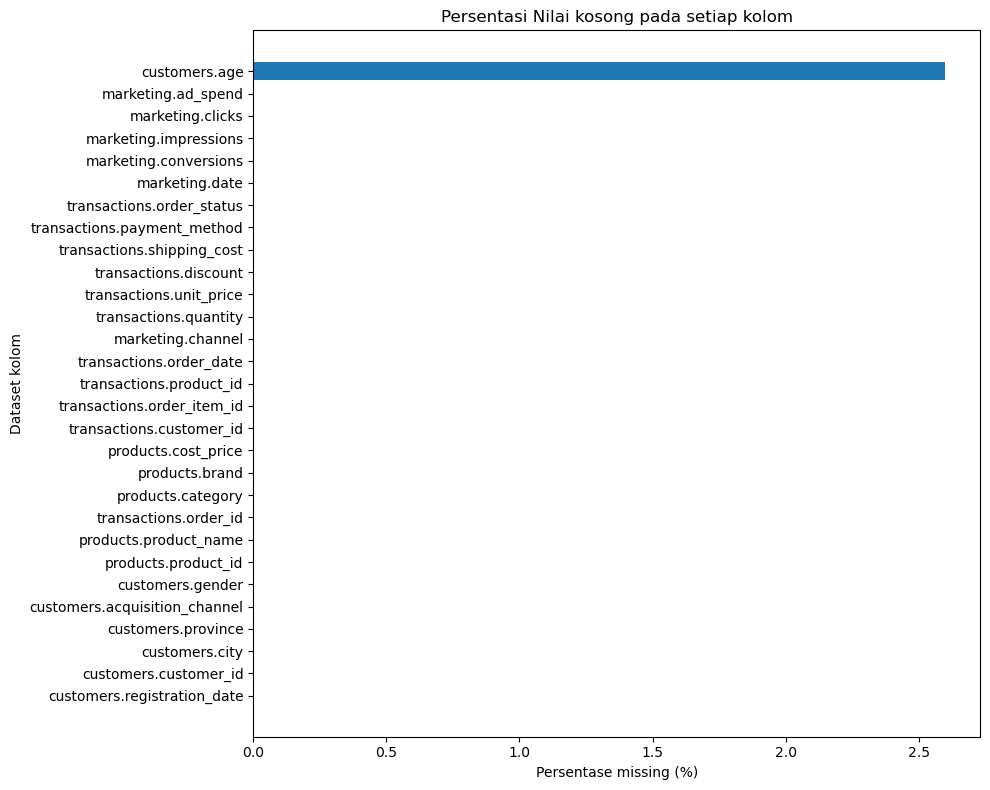

In [29]:
plot_df = semua_missing.sort_values('persen', ascending=True)

plt.figure(figsize=(10,8))
plt.barh(plot_df['label'], plot_df['persen'])
plt.title('Persentasi Nilai kosong pada setiap kolom')
plt.xlabel('Persentase missing (%)')
plt.ylabel('Dataset kolom')
plt.tight_layout()
plt.show

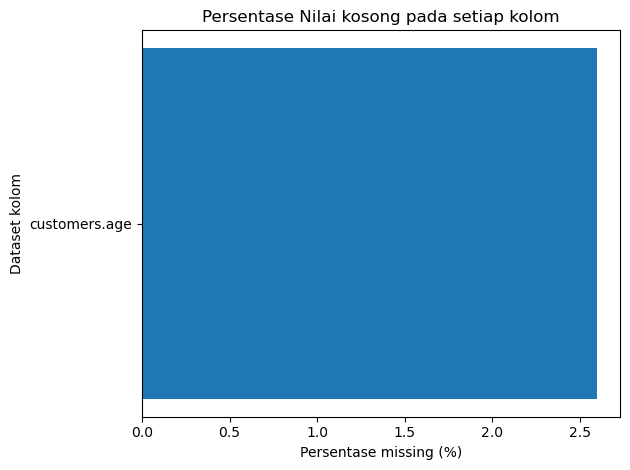

In [30]:
plot_df = plot_df[plot_df['persen'] > 0]

plt.figure()
plt.barh(plot_df['label'], plot_df['persen'])
plt.title('Persentase Nilai kosong pada setiap kolom')
plt.xlabel('Persentase missing (%)')
plt.ylabel('Dataset kolom')
plt.tight_layout()
plt.show()


-Soal 2.3

* *Duplikat yang tidak wajar*

In [31]:
print('customers :', customers['customer_id'].duplicated().sum())
print('products : ', products['product_id'].duplicated().sum())
print('transactions : ', transactions['order_item_id'].duplicated().sum())
print('marketing : ', marketing.duplicated(subset=['date', 'channel']).sum())

customers : 0
products :  0
transactions :  0
marketing :  0


* *Nilai yang tidak wajar*

In [32]:
print('quantity <= 0 :', (transactions['quantity'] <= 0).sum())
print('unit_price <= 0 :', (transactions['unit_price'] <= 0).sum())
print('discount < 0 :', (transactions['discount'] < 0).sum())
print('discount > 1 :', (transactions['discount'] > 1).sum())

quantity <= 0 : 0
unit_price <= 0 : 0
discount < 0 : 0
discount > 1 : 0


-Soal 2.4

In [33]:
transactions_bersih = transactions[(transactions['quantity'] > 0) & (transactions['discount'].between(0,1))].copy()
print(len(transactions), '->', len(transactions_bersih))

12710 -> 12710


Tidak ada perubahan dari yang terjadi dari pembersihan dataset `transactions` artinya data transaksi dipakai apa adanya

Tindakan yang akan di pilih adalah biarkan karena :
- Kolom `age` memiliki 78 nilai kosong nilai kosong (2.6%) dari 3000 pelanggan. Nilai kosong di biarkan, tidak di isi 0 atau rata" karena tidak ada bukti umur sebenarnya. Baris tersebut hanya dikeluarkan pada analisis yang memakai usia.

*Pertanyaan penalaran*

Jawaban:

Resikonya, seluruh tabel pelanggan yang umurnya kosong akan ikut terhapus, padahal umur tidak dipakai untuk mengaalisis metode pembayaran, jumlah pelanggan menyusut dan persentase metode pembayaran bisa bias kalau pelanggan yang umur nya kosong punya kebiasaan bayar yang berbeda

* **Soal 3**

-Soal 3.1

Trend bulanan               = order_date, pendapatan bersih | Rupiah per Bulan | Line chart

Pangsa metode Pembayaran    = payment_menthod, order_id | % dari total order unik | Bar chart berisi persen

profil usia                 = age | Jumlah pelanggan per rentang usia | Histogram

Hubungan harga-kuantitas    = unit_price, quantity | per item | Scatter

Kategori populer            = category, order_id | Jumlah order unik | Bar horizontal terurut

Pembatalan                  = order_status, order_id | % order canceled dari semua order | Bar chart persen


-Soal 3.2 / 3.3

**Sketsa 1** (Scatterplot)

Hubungan harga-kuantitas

Title   : Hubungan Harga Satuan dengan Kuantitas per-Item

Sumbu X : Harga Satuan (unit_price) dengan harga RP (Rupiah)

Sumbu Y : Kuantitas (quantity) dalam jumlah unit per item

Satuan  : 1 Titik = 1 Item Pesanan

* *Alternatif 1*

Line chart : Garis menghubungkan titik satu per satu, seolah ada urutannya. Padahal item pesanan tidak berurutan menurut harga. Garisnya jadinya acak-acakan dan menyesatkan.

* *Alternatif 2*

Pie chart : Pie hanya menunjukan bagian dari total. Ia tidak bisa menunjukkan hubungan antara dua angka (Harga dan Kualitas)

**Sketsa 2** (Horizontal Bar chart)

Kategori populer

Title : Jumlah Pesanan Unik per Kategori Produk (Pesanan Completed)

Sumbu X : Jumlah pesanan unik (order_id)

Sumbu Y : Kategori produk

Satuan : pesanan unik

* *Altenatif 1*

Pie chart : Klau irisan nilainya mirip, mata sulit membandingkan sudut atau luasnya. Nama kategori yang panjang juga susah ditaruh, dan urutan dari terbesar sulit di lihat.

* *Alternatif 2*

Line chart : Garis menyirantkan ada urutan atau perubahan berkelanjutan antar kategori, padahal kategori itu hanya nama dan tidak berurutan. Garis naik-turun jadi tidak bermakna.

*Pertanyaan Penalaran*

Jawaban :

Untuk proporsi, pakai bar chart berisi persen (sumbunya 0-100%) atau 100% stacked bar. Yang dibandingkan adalah baagian terhadap total, jadi sumbunya berupa persen dan penyebutnya harus jelas, yaitu "persen dari total order unik".

* Soal 4

In [34]:
# Validasi kategori
completed = transactions[transactions['order_status'] == 'completed']

m = completed.merge(
    products[['product_id', 'category']],
    on='product_id',
    how='left',
    validate='many_to_one'
)

print(len(completed), len(m))
print(m['category'].isna().sum())

11013 11013
0


Panjang data complete = 11013

Panjang data merge = 11013

Nilai kosong yang ada di data merge column category = 0

In [35]:
hasil = (m.groupby('category')['order_id']).nunique().sort_values(ascending=False)
print(hasil)

category
Kecantikan      1971
Buku            1777
Rumah Tangga    1710
Elektronik      1690
Olahraga        1616
Fashion         1463
Name: order_id, dtype: int64


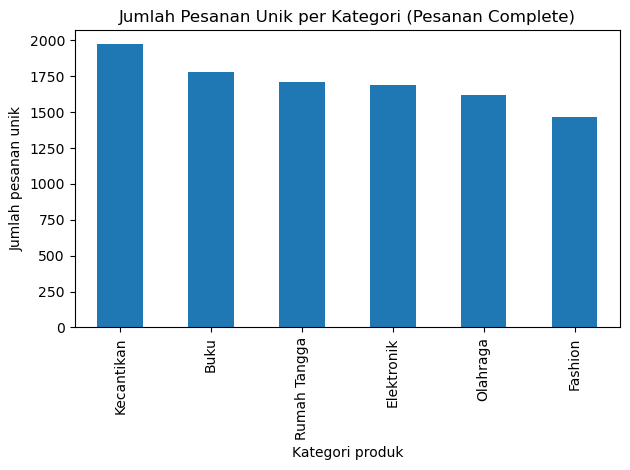

In [36]:
hasil.plot(kind='bar')
plt.title('Jumlah Pesanan Unik per Kategori (Pesanan Complete)')
plt.xlabel('Kategori produk')
plt.ylabel('Jumlah pesanan unik')
plt.tight_layout()
plt.show()

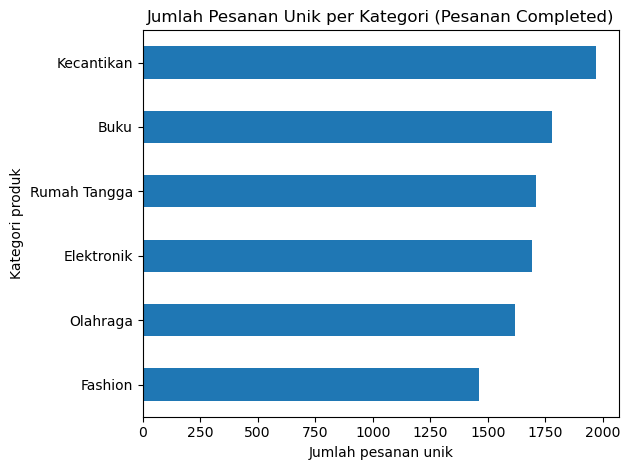

In [37]:
hasil.sort_values().plot(kind='barh')
plt.title('Jumlah Pesanan Unik per Kategori (Pesanan Completed)')
plt.xlabel('Jumlah pesanan unik')
plt.ylabel('Kategori produk')
plt.tight_layout()
plt.show()

* Vertikal : Nama kateogri ada di bawah, jadi harus diputar mirik kalau panjang. Kalau namanya panjang, susah dibaca.

* Horizontal : Nama katogeri di kiri dan terbaca lurus, jadi lebih nyaman untuk nama panjang. Peringatan dari atas ke bawah juga terasa alami seperti daftar.

*Pertanyaan Penalaran*

Jawaban :

Kalau satu order berisi dua produk dari kategori yang sama, kita menghitung pesanan, bukan item. Jadi order itu di hitung pesanan jadi membengkak. Kalau satu order berisi produk dari dua kategori berbeda, order itu di hitung satu kali di setiap kategori. Karena itu jumlah semua kategori bisa lebih besar dari jumlah total order.

* Soal 5

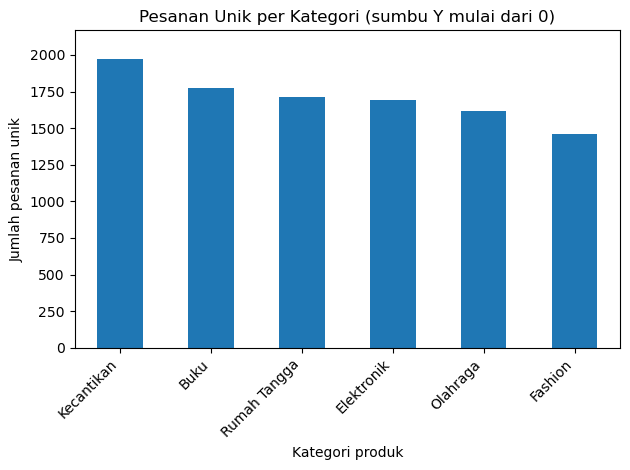

In [39]:
fig, ax = plt.subplots()
hasil.plot(kind='bar', ax=ax)
ax.set_ylim(0, hasil.max() * 1.1)
ax.set_title('Pesanan Unik per Kategori (sumbu Y mulai dari 0)')
ax.set_xlabel('Kategori produk')
ax.set_ylabel('Jumlah pesanan unik')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

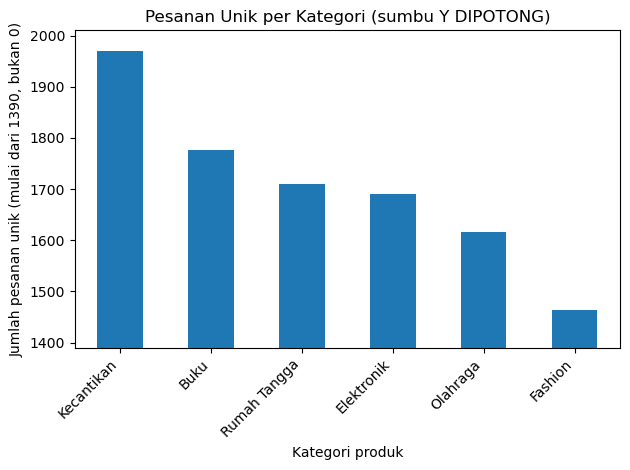

In [41]:
fig, ax = plt.subplots()
hasil.plot(kind='bar', ax=ax)
batas_bawah = hasil.min() * 0.95
ax.set_ylim(batas_bawah, hasil.max() * 1.02)
ax.set_title('Pesanan Unik per Kategori (sumbu Y DIPOTONG)')
ax.set_xlabel('Kategori produk')
ax.set_ylabel(f'Jumlah pesanan unik (mulai dari {batas_bawah:.0f}, bukan 0)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

* **Versi dipotong** : Selisih antara kategori terlihat sangat besar, padahal sebenarnya mungkin kecil. Contoh dari soal:98 vd 100 hanya selisih 2, tapi kalau sumbunya mulai dari 90, batang 100 terlihat berkali-kali lebih tinggi dari batang 98

* **Versi mulai dai 0** : Tinggi batang sebandingdengan angkanya, jadi perbedaanya terlihat apa adanya

* **Pilihan untuk laporan akhir** : Versi mulai dari 0, karena lebih adil dan tidak membuat pembaca salah menilai

*Pertanyaan penalaran*

Jawaban : 


Memotong sumbu tidak selalu salah. Pada bar chart, panjang batang mewakili nilai, jadi sumbu harus mulai dari 0, kalau tidak, selisih kecil terlihat besar dan menyesatkan. Pada line chart, yang dilihat adalah pola naik-turunnya, jadi sumbu boleh dipotong selama dinyatakan jelas.

* Soal 6

In [43]:
jumlah_kosong = customers['age'].isna().sum()
umur = customers['age'].dropna()

print('Umur kosong :', jumlah_kosong, f'({customers['age'].isna().mean()*100:.1f}%)')
print('Umur valid :', len(umur))
print('Termuda / tertua :', umur.min(), '/', umur.max())

Umur kosong : 78 (2.6%)
Umur valid : 2922
Termuda / tertua : 18.0 / 64.0


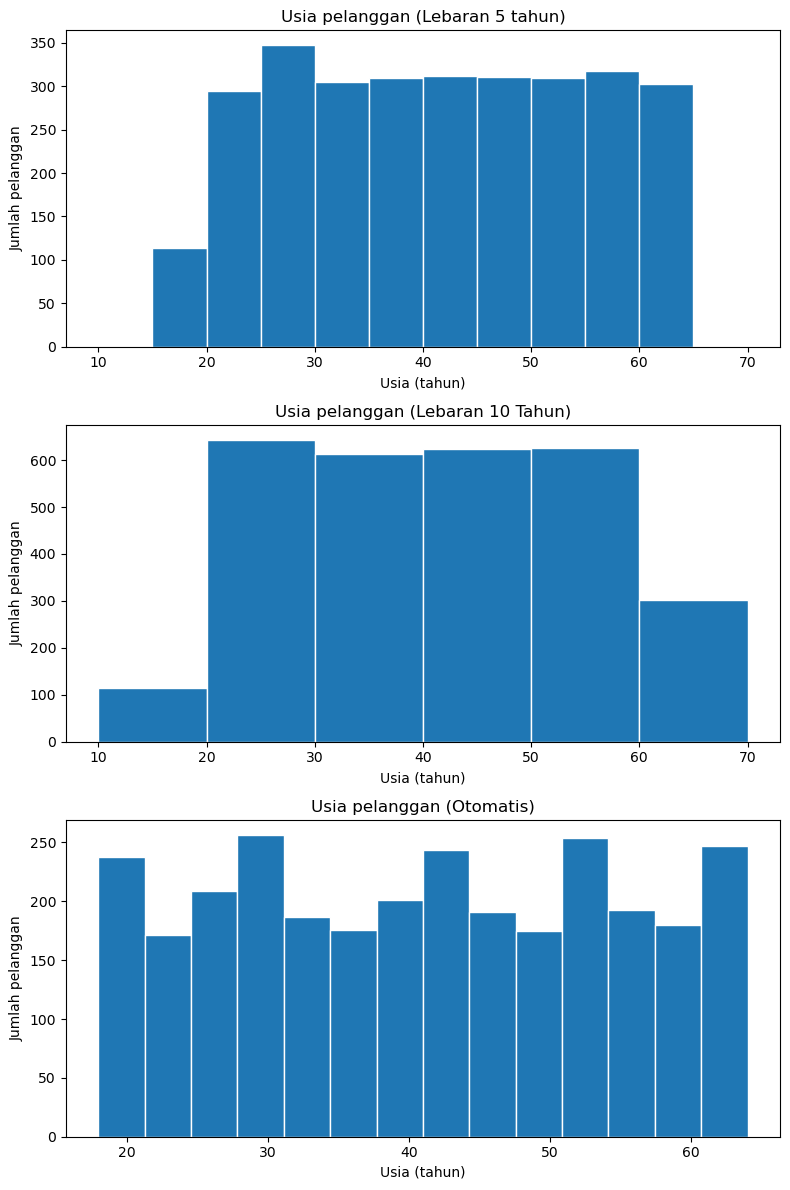

In [48]:
awal = int(umur.min() // 10 * 10)
akhir = int(umur.max() // 10 * 10 + 10)

aturan_bin = {'Lebaran 5 tahun': np.arange(awal, akhir + 5, 5), 'Lebaran 10 Tahun': np.arange(awal, akhir + 10, 10), 'Otomatis': 'auto',}

fig, axes = plt.subplots(3, 1, figsize=(8, 12), sharey=False)
for ax, (nama, bins) in zip(axes, aturan_bin.items()):
    ax.hist(umur, bins=bins, edgecolor='white')
    ax.set_title(f'Usia pelanggan ({nama})')
    ax.set_xlabel('Usia (tahun)')
    ax.set_ylabel('Jumlah pelanggan')
plt.tight_layout()
plt.show()

In [49]:
baris = []
for nama, bins in aturan_bin.items():
    jumlah, batas = np.histogram(umur, bins=bins)
    i = jumlah.argmax()
    baris.append({'Aturan bin': nama, 'Jumlah bin': len(jumlah), 'Kelompok paling ramai': f'{batas[i]:.0f} sampai {batas[i+1]:.0f} tahun', 'Jumlah pelanggan': jumlah[i],})

tabel_bin = pd.DataFrame(baris)
print(tabel_bin)

         Aturan bin  Jumlah bin Kelompok paling ramai  Jumlah pelanggan
0   Lebaran 5 tahun          12    25 sampai 30 tahun               347
1  Lebaran 10 Tahun           6    20 sampai 30 tahun               642
2          Otomatis          14    28 sampai 31 tahun               256


*Pertanyaan penalaran*

Jawaban : 

Kelompok usia terbesar tidak sepenuhnya stabil kalau dilihat dari batas kelompoknya: bin lebar 5 tahun memberi 25-30tahun, bin lebar 10 tahun memberi 20-30 tahun, dan bin otomatis memberi 28-31 tahun. Namun ketiganya sama-sama mencakup usia sekitar 28-30 tahun, jadi Kesimpulan umumnya stabil, yaitu pelanggan terbanyak berapa di akhir usia 20-an. Karena batas kelompok bergantung pada cara membagi bin, sebaiknya kelompok terbesar disebut sebagai rentang usia sekitar 28-30 tahun, bukan satu kelompok pasti.

* Soal 7

In [53]:
completed['gross_item_value'] = completed['quantity'] * completed['unit_price']

print(len(completed))
print(completed['gross_item_value'].describe())

11013
count    1.101300e+04
mean     6.218551e+05
std      2.006200e+06
min      1.100000e+04
25%      8.400000e+04
50%      2.060000e+05
75%      5.270000e+05
max      1.062600e+08
Name: gross_item_value, dtype: float64


/var/folders/8v/_f429jcx7lv2yx9w891n346h0000gn/T/ipykernel_2189/575161658.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  completed['gross_item_value'] = completed['quantity'] * completed['unit_price']


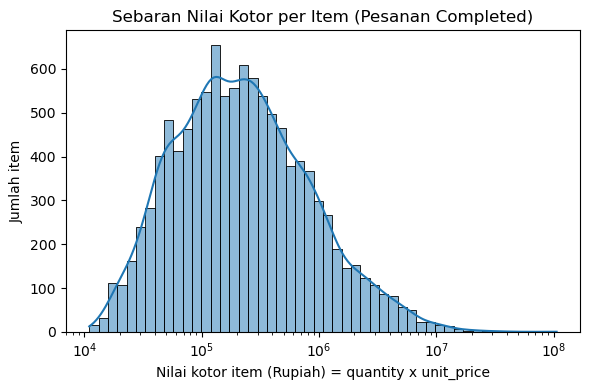

In [59]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.histplot(completed['gross_item_value'], bins=50, kde=True, ax=ax, log_scale=True)
ax.set_title('Sebaran Nilai Kotor per Item (Pesanan Completed)')
ax.set_xlabel('Nilai kotor item (Rupiah) = quantity x unit_price')
ax.set_ylabel('Jumlah item')
plt.tight_layout()
plt.show()

Menumpuk di kiri dengan ekor panjang ke kanan berarti miring ke kanan. Kalau ada beberapa puncak, bisa jadi ada kelompok produk dengan harga berbeda

In [55]:
s = completed['gross_item_value']
ringkas = pd.DataFrame({'Statistik': ['Jumlah item', 'Mean', 'Median', 'Persentil 25 (Q1)', 'Persentil 75 (Q3)', 'Maksimum'], 'Nilai': [len(s), s.mean(), s.median(), s.quantile(0.25), s.quantile(0.75), s.max()]})
print(ringkas.round(0))

           Statistik        Nilai
0        Jumlah item      11013.0
1               Mean     621855.0
2             Median     206000.0
3  Persentil 25 (Q1)      84000.0
4  Persentil 75 (Q3)     527000.0
5           Maksimum  106260000.0


*Pertanyaan penalaran*

Jawaban :

Ekor panjang ke kanan belum otomatis berarti outlier atau kesalahan data. Toko online menjual barang murah dan mahal sekaligus, jadi nilainya wajar beragam.